# Phytoplankton size structure and fisheries catch
> **Author:** Ryan Vandermeulen (NOAA Fisheries)</br>

![Phyto2Fish](https://raw.githubusercontent.com/ocean-satellite-tools/hyperdawg/main/tutorials/Phyto2Fish/Supporting_files/Graphic_gradation.png)

Well, hello there, friend! Welcome to the **Phyto2Fish** tutorial. We're going to implement a simple framework that uses phytoplankton size structure to explore how energy moves through marine food webs and ultimately supports fisheries production. Using satellite derived chlorophyll-*a*, we'll walk through how to estimate the relative contributions of pico-, nano-, and microphytoplankton, and use those fractions to calculate an adjustment to a trophic pathway length (ΔL) parameter. Then, we'll combine that information with satellite-derived net primary production (NPP) and meticulously compiled fisheries catch data from around the globe to see how well our predictions line up with actual catches. Let's do this!

*Note: I would like to disclose that instead of inflicting the psychological torture of navigating my raw code onto you, I asked ChatGPT to clean up my messiness and streamline/annote my code for this tutorial.*

## First, our libraries

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from pathlib import Path
import cartopy.crs as ccrs
import cartopy.feature as cfeature

## First, let's set the scene

Before we start tinkering with phytoplankton size structure, let's consider how we might estimate fisheries catch ($C_{fish}$) from satellite observations in the first place. The basic idea is that all those fish ultimately depend on energy entering the marine food web through primary production. Satellites give us a pretty remarkable view of how much carbon phytoplankton are producing across the global ocean, but not all of that production makes its way up to fish. Energy is lost along the way as organisms consume, respire, and transfer carbon through successive trophic levels. One relatively simple way to represent this relationship is through a trophodynamic formulation that combines net primary production ($NPP$), trophic transfer efficiency ($TE$), a scalar for transfer availability ($\alpha$), and the mean trophic level ($TL$) of harvested fish:

$C_{fish} = \alpha \times NPP \times TE^{(TL-1)}$

Slightly more detailed - here, $NPP$ represents the total, summed carbon produced within a given ecoregion (converted to "fish-equivalent" wet weight by a hand-wavy factor of 9), $TE$ describes the fraction of energy transferred between successive trophic levels, a harvesting fraction ($\alpha$) represents the proportion of available energy ultimately realized as fisheries catch, and the exponent ($TL - 1$) approximates the number of transfers between primary producers and harvested fish. Long story short, more primary production generally means more energy available to support fisheries, while each additional trophic transfer **exponentially** reduces the amount that ultimately reaches harvested fish. For example, fisheries targeting higher trophic-level predators like tuna require energy to pass through more steps in the food web, with losses occurring along the way. Fisheries targeting lower trophic-level species like sardines, on the other hand, benefit from shorter pathways between phytoplankton and the fish being harvested, meaning a greater fraction of the original energy from primary production can make its way into the catch.

This is the core foundational framework we're going to work with here, so let's take a moment to set some of the parameters that stay constant. Feel free to play around with them! If you're a fish nerd, you may have very strong opinions about these particular parameters. These terms can vary considerably among ecosystems, but based on the mean of ranges found in literature, we'll use a harvesting fraction ($\alpha$) of 0.175, a trophic transfer efficiency ($TE$) of 0.13, and our 9:1 conversion of carbon to fish-equivalent wet weight.

In [2]:
# Fisheries model parameters
alpha, TE, wet_weight = 0.175, 0.13, 9

## But there's a catch (eh? eh? ... I'll see myself out)

Our simple formulation above assumes that energy moves from phytoplankton to zooplankton in a single trophic transfer, with a fraction of that energy lost at each subsequent step up the fishy food web. In reality, things aren't always so straightforward. This is where phytoplankton size structure becomes an important consideration. In systems dominated by teeny tiny cyanobacteria, for example, much of the primary production may pass through the microbial loop, where small phytoplankton are consumed by protists and other microorganisms before a fraction of that energy eventually reaches larger zooplankton and fish. Each additional step comes with an energetic cost, meaning that less of the original primary production may be available to support fisheries. Larger phytoplankton, on the other hand, can be consumed more directly by larger zooplankton, providing a shorter pathway to fish.

The figure below illustrates this idea with three highly simplified food chains representing pico-, nano-, and microphytoplankton. Of course, real marine food webs are considerably messier than these tidy little pathways. But the general idea is that smaller phytoplankton often require more intermediate consumers to transfer their production to fish, potentially reducing the efficiency of that transfer.

![Phyto2Fish_simple_foodweb](Supporting_files/Graphic_small.png)

Like I said, this is a grossly oversimplified representation of the marine food web, but you get the picture. Now, let's see what we if can introduce some of this nuance into our basic fisheries catch framework.

## Let the phytoplankton partitioning begin!

Quite a gentleman IRL, Dr. Bob Brewin compiled some handy empirical relationships that allow us to estimate phytoplankton size structure from satellite-derived chlorophyll-*a* concentrations ([Brewin et al. 2011](https://doi.org/10.1364/AO.50.004535)). Using these relationships, we can estimate the relative (%) contributions of pico-, nano-, and microphytoplankton to total chlorophyll-*a*. The basic concept is as follows. Bob Brewin's size class model can be expressed through two simple exponential equations, such that the chlorophyll concentrations of the combined pico + nanophytoplankton population ($C_{p,n}$; cells <20 µm), and the picophytoplankton population ($C_{p}$; cells <2 µm), can be expressed as:

$C_{p,n} = C_{p,n}^m [1 - exp(-\dfrac {D_{p,n}}{C_{p,n}^m} C)] $

and

$C_{p} = C_{p}^m [1 - exp(-\dfrac {D_{p}}{C_{p}^m} C)] $

where $C$ is the total chlorophyll concentration from the satellite data, and $C_{p,n}^m$ and $C_{p}^m$ are constant asymptotic maximum values for the respective size class, and $D_{p,n}$ and $D_{p}$ (also constants) determine the fraction of total chlorophyll in the two size classes. Moving forward, through a simple difference, we can isolate the nanophytoplankton ($C_{n}; 2-20 µm$) by subtracting the above terms. 

$C_{n} = C_{p,n} - C_{p} $

and then, the microphytoplankton ($C_{m}$; >20 µm) as:

$C_{m} = C - C_{p,n} $

The fraction of each phytoplankton size class to total chlorophyll concentration ($f_p, f_n, f_m$) can then be calculated by dividing the size-specific chlorophyll concentration ($C_p, C_n, C_m$) by the total chlorophyll concentration ($C$) from satellite ocean color data. If your eyes are crossed, no worries, just be assured that someone spent a considerable amount of time figuring this all out, and now we can go with the maths :-) The constants below can be changed for different regions (see Table 4.2 in the [IOCCG report #15](https://ioccg.org/wp-content/uploads/2018/09/ioccg_report_15_2014.pdf)), but we're rolling with coefficients that are meant to work on global scales. 

![Is this clear?](https://raw.githubusercontent.com/fish-pace/2025-tutorials/main/Supporting_files/Princess_bride.gif)!

In [3]:
# Brewin (2011) size-class model coefficients
Cpm, Cpmn, Dp, Dpn = 0.13, 0.77, 0.80, 0.94

def size_fractions(chl):
    chl = np.asarray(chl, dtype=float)
    cp = Cpm * (1 - np.exp(-Dp * chl / Cpm))
    cpn = Cpmn * (1 - np.exp(-Dpn * chl / Cpmn))
    return cp / chl, (cpn - cp) / chl, (chl - cpn) / chl

## Let's give those food webs a little stretch!

Alright, we've established that smaller phytoplankton can introduce additional steps into marine food webs, and we've figured out how to estimate the relative contributions of our three phytoplankton size classes. Now, let's put those pieces together. Estimateing fish catch via Phyto2Fish ($C_{P2F}$), we account for these differences by introducing a size-structured trophic-level extension ($\Delta L$) into our original fisheries catch equation:

$C_{P2F} = \alpha \times NPP \times TE^{(TL-1+\Delta L)}$

 We calculate $\Delta L$ as a weighted sum of the phytoplankton size fractions we derived earlier:

$\Delta L = f_{micro}\omega_{micro} + f_{nano}\omega_{nano} + f_{pico}\omega_{pico}$

Here, the f terms represent the relative contributions of micro-, nano-, and picophytoplankton, while the corresponding ω values control their influence on ΔL. Importantly, **these coefficients aren't meant to represent the literal number of trophic transfers associated with each phytoplankton size class**. Instead, they control the magnitude and shape of the relationship between chlorophyll-a and $\Delta L$. Our configuration ($\omega_{micro}=0$, $\omega_{nano}=0.15$, $\omega_{pico}=2.5$) produces a relationship in which $\Delta L$ increases as smaller phytoplankton become more prevalent, representing the additional energy losses associated with longer trophic pathways. We're not changing how much carbon phytoplankton produce, or the trophic level of the fish being harvested. We're simply adjusting the effective length of the food-web pathway connecting the two. When smaller phytoplankton dominate, $\Delta L$ introduces additional trophic transfers, reducing the amount of production expected to reach harvested fish. When larger phytoplankton dominate, $\Delta L$ approaches zero, and we recover the original model. So, how do we put a number on those extra transfers?

The plot below shows how phytoplankton size fractions change across a range of chlorophyll-a concentrations, and how those changes translate into $\Delta L$. Go ahead, twist those knobs and see what happens!

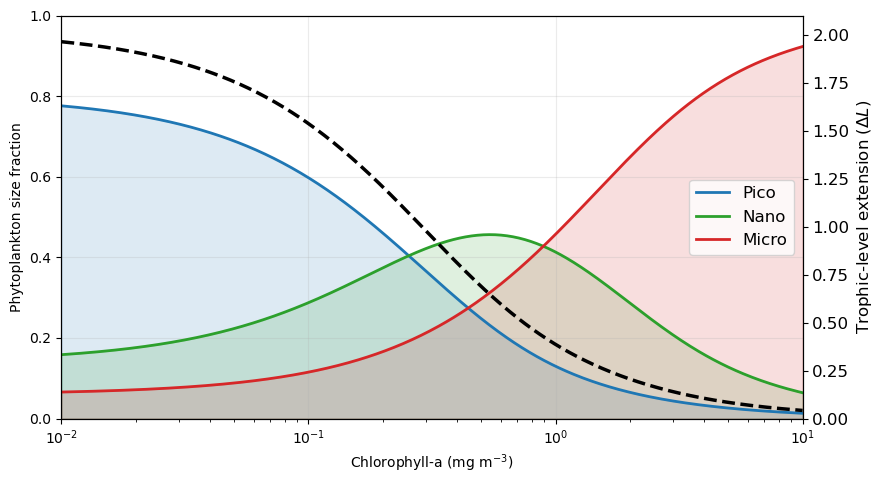

In [4]:
# Editable size-specific transfer weighting coefficients (pico, nano, micro)
omega_pico, omega_nano, omega_micro = 2.5, 0.15, 0.0

def delta_tl(chl):
    fp, fn, fm = size_fractions(chl)
    return fp * omega_pico + fn * omega_nano + fm * omega_micro

chl_range = np.logspace(-2, 1, 500)
fp, fn, fm = size_fractions(chl_range)
fig, ax = plt.subplots(figsize=(9, 5))
plt.rcParams.update({'font.size': 12})
for fraction, name, color in zip((fp, fn, fm), ('Pico', 'Nano', 'Micro'), ('tab:blue', 'tab:green', 'tab:red')):
    ax.plot(chl_range, fraction, label=name, color=color, lw=2)
    ax.fill_between(chl_range, fraction, color=color, alpha=0.15)
ax.set(xscale='log', xlabel='Chlorophyll-a (mg m$^{-3}$)', ylabel='Phytoplankton size fraction', ylim=(0, 1))
ax2 = ax.twinx()
ax2.plot(chl_range, delta_tl(chl_range), 'k--', lw=2.5, label=r'$\Delta L$')
ax2.set(ylabel=r'Trophic-level extension ($\Delta L$)', ylim=(0, 2.1))
ax.legend(loc='center right')
ax.set_xlim(0.01, 10)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Here is where the magic happens

*A quick caveat*: **we are not attempting to predict how many fish will actually be caught in a given year**. Fisheries catches depend on fishing effort, management, market conditions, population dynamics, and plenty of other factors that aren't explicitly represented here. Instead, we're exploring whether accounting for phytoplankton size structure improves our ability to describe broad-scale differences in fisheries production relative to a simpler model based on NPP and trophic level alone.

To evaluate our approach, we apply the model across the Marine Ecoregions of the World (MEOWs), using annual estimates of satellite-derived net primary production ($NPP$) and chlorophyll-a, alongside reported fisheries catch and mean trophic level data from the ([Sea Around Us project](https://www.seaaroundus.org/data/#/marine-trophic-index)). By combining these datasets, we can estimate how much of that primary production might ultimately support fisheries, and compare our predictions against reported catches. Now, about the data... I went back and forth about including all the data extraction and processing procedures in this notebook. I won't lie, some of it was a pain. Between manually downloading datasets, temporal interpolations, resampling, and wrangling files across different virtual computing environments (which have the audacity of imposing storage limits!), there were quite a few moving parts. At peak irritation level, I discovered that the MEOWs used by the Sea Around Us dataset *occasionally* have slightly different names than those in the MEOW shapefile. Ultimately, I decided to spare you the data-wrangling adventure and provide the processed, matched up datasets directly. The extraction, aggregation, and processing procedures are described in the associated manuscript, but I've left those steps out here to keep things approachable (and because of those pesky storage limitations).

Below, we load the processed datasets, reconcile the ecoregion names, combine everything into a single table, and calculate our Phyto2Fish predictions using the parameters we defined above. We'll also calculate the logarithmic bias between predicted and observed catch, which will come in handy when we start evaluating model performance.

A note about polar regions: See this line?
>
>data = data[(data.Lat_Zone != 'Polar') & (data.NPP > 0) & (data.CHL > 0) & (data.Catch > 0) & data.TL.notna()].copy()
>
Comment that out (or just remove the polar exclusion) if you'd like to explore those regions too. Honestly, including them didn't make a huge difference in the overall statistics, but the sparse and seasonally limited satellite observations at high latitudes, combined with our assumptions about annual primary production, made me a little queasy. So we left them out of the main analysis.

One more thing! You'll notice that we also load annual mean sea surface temperature (SST) and fishing effort data. SST wasn't used in the original model, while fishing effort provides some useful context for interpreting differences between predictions and reported catch. Neither is required to calculate Phyto2Fish, but perhaps you'll find something interesting by exploring them further. **Eat the gatekeepers!**


In [5]:
# Read data
npp = pd.read_csv('Supporting_files/MEOW_integrated_NPP_1998_2025_tonnesC.csv')
chl = pd.read_csv('Supporting_files/MEOW_annual_OCCCI4km_mean_CHL_1998_2025.csv')
sst = pd.read_csv('Supporting_files/MEOW_annual_mean_SST_1998_2025.csv')
fishing_hours = pd.read_csv('Supporting_files/MEOW_mean_monthly_fishing_hours_2012_2024.csv')
catch = pd.read_csv('Supporting_files/MEOW_catch_smoothed_1998_present.csv')
tl = pd.read_csv('Supporting_files/MEOW_mtl_smoothed_1998_present.csv')
lookup = pd.read_csv('Supporting_files/SAU_MEOW_lookup.csv')
meow = gpd.read_file('Supporting_files/meow_ecos.shp')

# Translate SAU column names to MEOW ecoregion names.
rename = {f"MEOW_{r.meow_id}_{r.meow_name}".replace(' ', '_').replace('-', '_').replace('/', '_'): r.meow_name for r in lookup.itertuples()}
catch, tl = catch.rename(columns=rename), tl.rename(columns=rename)
common = sorted(set(npp) & set(chl) & set(catch) & set(tl) - {'year'})
print(f'Matched MEOWs: {len(common)}')

# Combine observations by MEOW and year, add fishing effort and latitude zones
def to_long(df, value):
    return df[['year'] + common].melt('year', var_name='MEOW', value_name=value) 
data = to_long(npp, 'NPP').merge(to_long(chl, 'CHL')).merge(to_long(catch, 'Catch')).merge(to_long(tl, 'TL'))
data = data.merge(fishing_hours[['MEOW', 'mean_monthly_fishing_hours']], on='MEOW', how='left')
zones = meow[['ECOREGION', 'Lat_Zone']].drop_duplicates().rename(columns={'ECOREGION': 'MEOW'})
data = data.merge(zones, on='MEOW', how='left')
# Exclude polar regions and invalid observations
data = data[(data.Lat_Zone != 'Polar') & (data.NPP > 0) & (data.CHL > 0) & (data.Catch > 0) & data.TL.notna()].copy()

# Baseline and Phyto2Fish predictions
data['Delta_L'] = delta_tl(data.CHL)
data['Baseline'] = alpha * data.NPP * wet_weight * TE ** (data.TL - 1)
data['Predicted'] = alpha * data.NPP * wet_weight * TE ** (data.TL - 1 + data.Delta_L)
data['Baseline_Log_bias'] = np.log10(data.Baseline / data.Catch)
data['Log_bias'] = np.log10(data.Predicted / data.Catch)
effort_data = data.dropna(subset=['mean_monthly_fishing_hours']).copy()

print(f'Valid ecoregion-years: {len(data)} | Years: {data.year.min()}–{data.year.max()}')
data.head()

Matched MEOWs: 206
Valid ecoregion-years: 4114 | Years: 1998–2019


,year,MEOW,NPP,CHL,Catch,TL,mean_monthly_fishing_hours,Lat_Zone,Delta_L,Baseline,Predicted,Baseline_Log_bias,Log_bias
0,1998,Adriatic Sea,1.467606e+07,0.648062,252279.4,3.390,98548.796011,Temperate,0.560098,176284.686262,56225.870202,-0.155667,-0.651946
1,1999,Adriatic Sea,1.380182e+07,0.589475,247520.2,3.376,98548.796011,Temperate,0.605009,170587.130775,49644.793556,-0.161664,-0.697737
2,2000,Adriatic Sea,1.359647e+07,0.635991,237026.8,3.372,98548.796011,Temperate,0.568820,169426.161372,53085.258233,-0.145817,-0.649824
3,2001,Adriatic Sea,1.366810e+07,0.643037,223398.6,3.378,98548.796011,Temperate,0.563697,168246.452271,53269.461960,-0.123135,-0.622602
4,2002,Adriatic Sea,1.481160e+07,0.931520,210637.8,3.392,98548.796011,Temperate,0.411120,177188.274003,76587.689293,-0.075101,-0.439377


## How'd we do? 

Because we scientists are gluttons for scatter plots, let's see how our predicted fisheries catch stacks up against the real thing! In our created plot, the dashed line represents a perfect match between observed and predicted catch. Points above the line indicate overprediction, while points below indicate underprediction. We've also included a few statistics to help quantify how well the model performs. Remember, we're trying to capture broad-scale patterns in fisheries production, not predict exactly how many fish will end up on someone's dinner plate. Obviously, there's a lot more going on in food web + fleet dynamics than bottom-up forcing from our phytoplankton overlords.

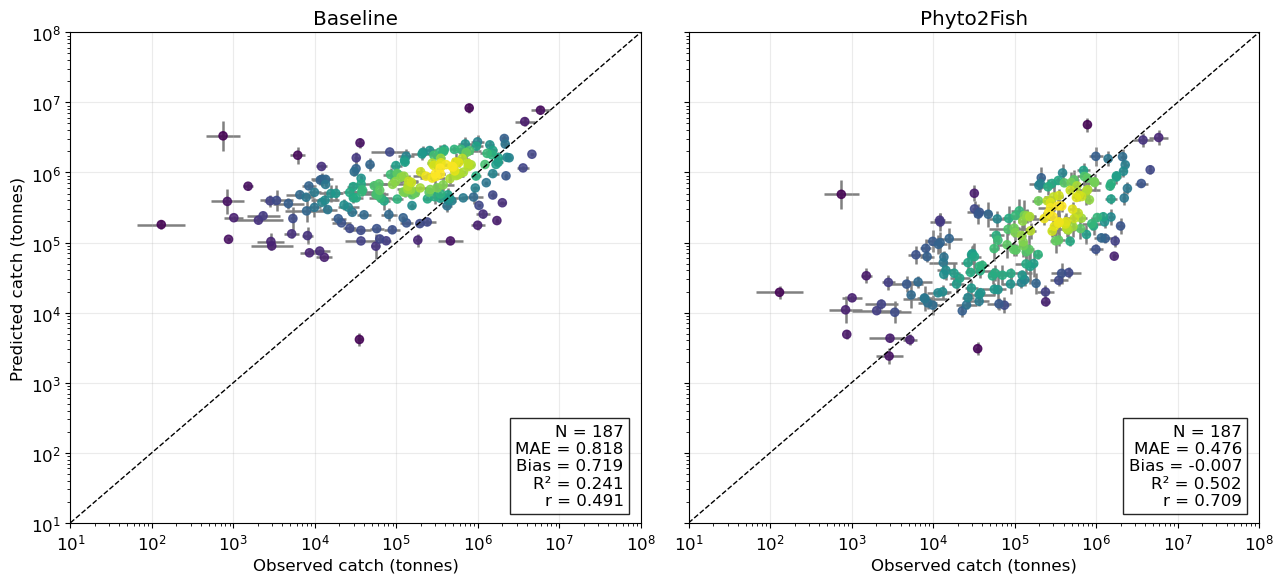

In [6]:
# Geometric mean ± 1 geometric standard deviation per MEOW
def geom_stats(x):
    log_x = np.log10(x)
    return pd.Series({'mean': 10**log_x.mean(), 'low': 10**(log_x.mean() - log_x.std()), 'high': 10**(log_x.mean() + log_x.std())})

variables = ['Catch', 'Baseline', 'Predicted']
avg = data.groupby('MEOW')[variables].apply(lambda g: pd.concat({var: geom_stats(g[var]) for var in variables})).unstack()

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)
for ax, model in zip(axes, ['Baseline', 'Predicted']):
    x, y = avg[('Catch', 'mean')].to_numpy(), avg[(model, 'mean')].to_numpy()
    lx, ly = np.log10(x), np.log10(y)
    error = ly - lx
    mae, bias, r = np.mean(np.abs(error)), np.mean(error), np.corrcoef(lx, ly)[0, 1]
    density = gaussian_kde(np.vstack([lx, ly]))(np.vstack([lx, ly]))
    order = np.argsort(density)
    xerr = [x - avg[('Catch', 'low')], avg[('Catch', 'high')] - x]
    yerr = [y - avg[(model, 'low')], avg[(model, 'high')] - y]
    ax.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', ecolor='0.5', lw=1.8, zorder=1)
    ax.scatter(x[order], y[order], c=density[order], s=35, alpha=0.85, zorder=2)
    ax.plot([1e1, 1e8], [1e1, 1e8], 'k--', lw=1)
    ax.set(xscale='log', yscale='log', xlim=(1e1, 1e8), ylim=(1e1, 1e8), xlabel='Observed catch (tonnes)', title=model)
    ax.text(0.97, 0.03, f'N = {len(x)}\nMAE = {mae:.3f}\nBias = {bias:.3f}\nR² = {r*r:.3f}\nr = {r:.3f}', transform=ax.transAxes, ha='right', va='bottom', bbox={'facecolor': 'white', 'alpha': 0.85})
    ax.grid(alpha=0.25)
axes[0].set_ylabel('Predicted catch (tonnes)')
axes[1].set_title('Phyto2Fish')
plt.tight_layout()
plt.show()

## Mappy time!

Let's put all this in a little spatial context. The map we'll generate below will show the average difference between the Phyto2Fish-predicted and observed fisheries catch across the MEOWs. Red regions indicate where our model overpredicts catch, while blue regions indicate underprediction. The closer to white, the better the agreement. Darker gray areas represent regions that were excluded from the analysis or lacked sufficient data, including regions for which fisheries catch data were unavailable from Sea Around Us (e.g., Antarctica).

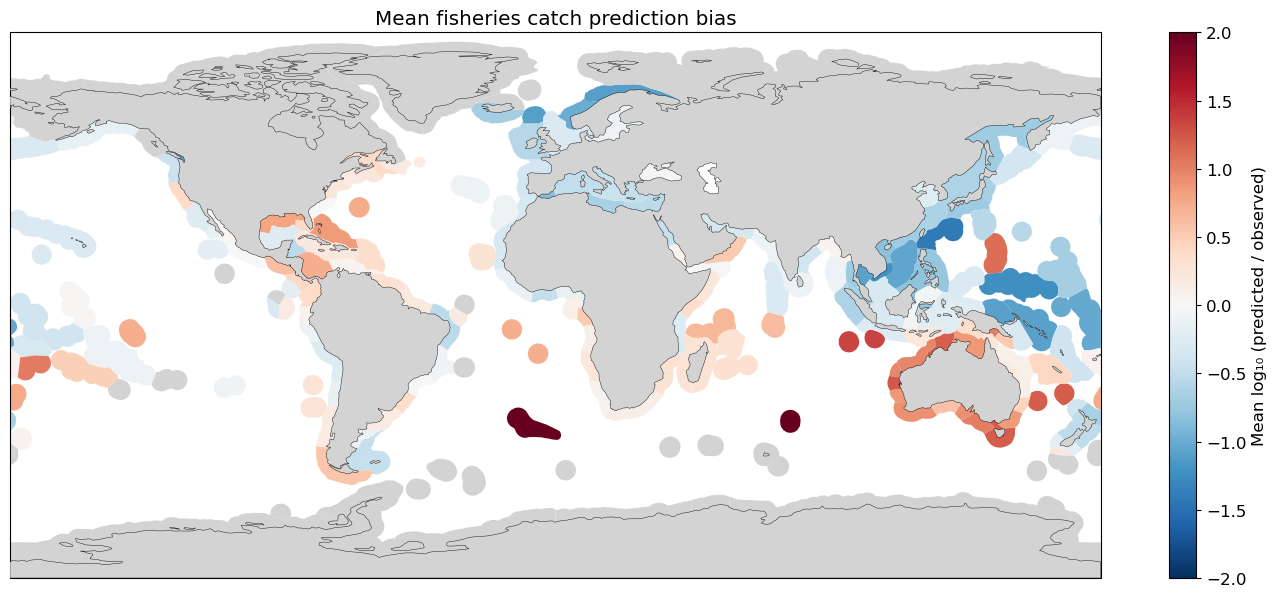

In [7]:
# Switch 'Log_bias' to 'Baseline_Log_bias' to view baseline model bias instead
mean_bias = data.groupby('MEOW', as_index=False)['Log_bias'].mean()
map_data = meow.merge(mean_bias, left_on='ECOREGION', right_on='MEOW', how='left')

fig, ax = plt.subplots(figsize=(14, 6), subplot_kw={'projection': ccrs.PlateCarree()})
map_data.plot(column='Log_bias', ax=ax, cmap='RdBu_r', vmin=-2, vmax=2, legend=True, missing_kwds={'color': 'lightgray'}, legend_kwds={'label': 'Mean log₁₀ (predicted / observed)'})
ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='black', linewidth=0.3, zorder=3)
ax.set(xlabel='Longitude', ylabel='Latitude', title='Mean fisheries catch prediction bias')
plt.tight_layout()
plt.show()

## Exploring marine ecosystems around the world

You want to get fancy?? Yeah you do. Let's interactively explore individual marine ecoregions and see how their environmental conditions, phytoplankton communities, and fisheries compare. Select an 'ecoregion' from the dropdown menu, and the dashboard will summarize nine indicators, from sea surface temperature and primary production to observed and predicted fisheries catch. The accompanying map provides a little geographic context. You can change which variable is displayed and zoom in or out to explore neighboring ecosystems. A few things to know before diving in:

- **Environmental conditions:** Sea surface temperature and chlorophyll-*a* are shown as trends per decade over 1998–2025. The other annual indicators are summarized as their mean ± standard deviation over the available model period (1998–2019). Arrows indicate statistically significant increases or decreases (p < 0.05).
- **Fisheries catch:** We're comparing observed catches with two mechanistic estimates. The baseline model uses primary production and the catch-weighted mean trophic level, while the size-adjusted model (Phyto2Fish) also accounts for the additional trophic transfers associated with smaller phytoplankton.
- **Fishing activity:** Apparent fishing effort comes from Global Fishing Watch satellite-based vessel tracking. These are summarized average monthly fishing hours over 2012–2024, and we also report the fishing effort magnitude relative to others worldwide (percentile). Keep in mind that these are total hours, not fishing intensity per unit area.

>

So go ahead, pick somewhere interesting. Does the model perform better in productive coastal waters or in regions dominated by smaller phytoplankton? Do changes in phytoplankton communities correspond with changes in predicted fisheries production? And where does the model seem to miss something important? 

In [8]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import ecosystem_dashboard as dash
import ecosystem_viewer as viewer

dash.configure(data=data, sst=sst, chl=chl, meow=meow, alpha=alpha, TE=TE, wet_weight=wet_weight)
viewer.launch(region_name='Carolinian', map_variable='Catch', zoom=2.00);

Output()

## Wrapping things up

Well, there you have it! We've journeyed from teeny tiny phytoplankton to fisheries catch, and sprinkled in a little satellite oceanography and trophic ecology along the way. Hopefully, this tutorial has adequetely conveyed that knowing how much carbon phytoplankton produce only tells us part of the story. What happens to that carbon as it moves through the food web matters too, and even a relatively simple adjustment for phytoplankton size structure can help us better understand differences in fisheries catch across the ocean. Of course, our little model leaves plenty out. Fish move, food webs are messy, and what ultimately gets caught depends on everything from ocean conditions and population dynamics to fishing activity and management decisions. We're certainly not predicting exactly how many fish will be caught, much less how many should be caught. The goal here isn't to build a perfect fisheries model. It's to explore how differences in primary production, phytoplankton size structure, and trophic pathways might help explain why some marine ecosystems support more fisheries catch than others.

What still continues to blow my mind is that we're using observations collected by satellites hundreds of kilometers above the ocean to explore microscopic level processes that manifest through the entire collective marine food web. We can't follow every bite, trace every carbon atom, or see the fish themselves from orbit, but phytoplankton provide us with a remarkable window into the biological workings of the ocean at scales we simply can't achieve through traditional observations alone. And we're only getting started! With NASA's Plankton, Aerosol, Cloud, ocean Ecosystem (PACE) mission, hyperspectral ocean color measurements are opening up new opportunities to distinguish phytoplankton groups based on their optical signatures, rather than relying primarily on chlorophyll-*a* concentration to infer community structure. Imagine what we might learn about fisheries production as these observations become increasingly useful for characterizing the phytoplankton communities at the base of marine food webs! There are plenty of ways to improve on what we've done here, and hopefully this tutorial leaves you with a few ideas of your own. Thanks for coming along for the ride!